# Modelo especialista: Alergia e Frieira

## Bibliotecas utilizadas

In [2]:
import numpy as np
import os
import re
import shutil
from matplotlib import pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
from scipy.signal import savgol_filter
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, InputLayer, Masking
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.utils import to_categorical

## Definição das classes

In [3]:
actions = ['Alergia', 'Frieira']
label_map = {label: num for num, label in enumerate(actions)}
num_frames = 30 

In [4]:
label_map

{'Alergia': 0, 'Frieira': 1}

## Detecção do início do movimento

In [5]:
def get_video_dirs(root_dir, class_names):
    #Lista (classe, nome, caminho) de todas as pastas de vídeo
    video_infos = []
    for cls in class_names:
        class_dir = os.path.join(root_dir, cls)
        if not os.path.isdir(class_dir):
            print(f"Atenção: diretório de classe não encontrado: {class_dir}")
            continue
        for entry in os.listdir(class_dir):
            video_path = os.path.join(class_dir, entry)
            if os.path.isdir(video_path):
                video_infos.append((cls, entry, video_path))
    return video_infos


def natural_sort_key(fname):
    #Ordena 2.npy antes de 10.npy
    parts = re.split(r'(\d+)', fname)
    return [int(p) if p.isdigit() else p.lower() for p in parts]


def adaptive_motion_start(motion_energy, min_baseline_frames=5, second_window=(10, 20), N=5):
    #Início do movimento: primeiro trecho de N frames com energia acima do limiar (média + desvio dos primeiros frames)
    motion_idx = 0
    baseline = np.mean(motion_energy[:min_baseline_frames]) + np.std(motion_energy[:min_baseline_frames])

    for i in range(len(motion_energy) - N):
        if np.all(motion_energy[i:i+N] > baseline):
            motion_idx = i
            break

    #Se o movimento já começa nos primeiros frames, recalcula o limiar com uma janela mais adiante
    if motion_idx <= min_baseline_frames:
        start, end = second_window
        if end < len(motion_energy):
            baseline = np.mean(motion_energy[start:end]) + 2 * np.std(motion_energy[start:end])
            for i in range(len(motion_energy) - N):
                if np.all(motion_energy[i:i+N] > baseline):
                    motion_idx = i
                    break

    return motion_idx, baseline


def plot_deteccao(lh_y_smooth, rh_y_smooth, motion_energy, baseline, motion_idx, pasta_figuras):
    #Salva as figuras da detecção de movimento (posição das mãos e energia do movimento)
    os.makedirs(pasta_figuras, exist_ok=True)
    formatter = FuncFormatter(lambda x, _: f"{x:.2f}".replace(".", ","))

    with plt.rc_context({"text.usetex": usar_latex, "font.family": "serif"}):
        plt.figure(figsize=(8, 4))
        plt.plot(lh_y_smooth, label="Posição da mão esquerda", color='blue')
        plt.plot(rh_y_smooth, label="Posição da mão direita", color='red')
        plt.axvline(motion_idx, color='green', linestyle='--', label=f"Início do movimento ({motion_idx})")
        plt.xlabel("Quadro")
        plt.ylabel("Posição das mãos")
        plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
        plt.gca().yaxis.set_major_formatter(formatter)
        plt.legend()
        plt.tight_layout()
        plt.savefig(os.path.join(pasta_figuras, "maos.pdf"))
        plt.show()

        plt.figure(figsize=(8, 4))
        plt.plot(motion_energy, label="Energia do movimento", color='purple')
        plt.axhline(baseline, color='orange', linestyle='--', label="Limiar adaptativo")
        plt.axvline(motion_idx, color='green', linestyle='--', label=f"Início do movimento ({motion_idx})")
        plt.xlabel("Quadro")
        plt.ylabel("Energia")
        plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
        plt.gca().yaxis.set_major_formatter(formatter)
        plt.legend()
        plt.tight_layout()
        plt.savefig(os.path.join(pasta_figuras, "mov.pdf"))
        plt.show()


def detect_motion_start(video_dir, target_count, plot=False, pasta_figuras=None):
    #Retorna os target_count frames a partir do início do movimento, o índice de início e o limiar
    files = sorted([f for f in os.listdir(video_dir) if f.endswith(".npy")], key=natural_sort_key)
    if len(files) == 0:
        print(f"[{video_dir}] Nenhum arquivo .npy encontrado.")
        return [], 0, 0.0

    keypoints = []
    for f in files:
        arr = np.load(os.path.join(video_dir, f))
        if arr.ndim == 1:
            arr = arr.reshape(-1, 3)
        keypoints.append(arr)
    keypoints = np.stack(keypoints)

    #Índices das mãos esquerda e direita (os 33 primeiros pontos são da pose)
    lh_indices = list(range(33, 54))
    rh_indices = list(range(54, 75))

    #Centro de cada mão em cada frame (NaN quando alguma das mãos não foi detectada)
    lh_centers, rh_centers = [], []
    for frame in keypoints:
        lh = frame[lh_indices, :]
        rh = frame[rh_indices, :]
        if np.all(lh == 0) or np.all(rh == 0):
            lh_centers.append([np.nan, np.nan])
            rh_centers.append([np.nan, np.nan])
            continue
        lh_centers.append(np.nanmean(lh[:, :2], axis=0))
        rh_centers.append(np.nanmean(rh[:, :2], axis=0))

    lh_centers = np.array(lh_centers)
    rh_centers = np.array(rh_centers)

    #Mantém só os frames em que as duas mãos foram detectadas
    valid_mask = ~np.isnan(lh_centers[:, 0]) & ~np.isnan(rh_centers[:, 0])
    if not np.any(valid_mask):
        print(f"[{video_dir}] nenhum frame válido após filtrar zeros.")
        return files[:target_count], 0, 0.0

    valid_files = [f for i, f in enumerate(files) if valid_mask[i]]
    lh_centers = lh_centers[valid_mask]
    rh_centers = rh_centers[valid_mask]

    if len(lh_centers) < 5:
        print(f"[{video_dir}] poucos frames válidos ({len(lh_centers)}).")
        return valid_files[:target_count], 0, 0.0

    #Posição vertical das mãos suavizada (Savitzky-Golay) e energia do movimento (soma das velocidades)
    lh_y_smooth = savgol_filter(lh_centers[:, 1], window_length=5, polyorder=3)
    rh_y_smooth = savgol_filter(rh_centers[:, 1], window_length=5, polyorder=3)
    motion_energy = np.abs(np.gradient(lh_y_smooth)) + np.abs(np.gradient(rh_y_smooth))

    motion_idx, baseline = adaptive_motion_start(motion_energy)

    if plot:
        plot_deteccao(lh_y_smooth, rh_y_smooth, motion_energy, baseline, motion_idx, pasta_figuras)

    #Frames a partir do início do movimento (repete o último se faltar)
    chosen_files = valid_files[motion_idx:motion_idx + target_count]
    if len(chosen_files) < target_count and len(chosen_files) > 0:
        chosen_files += [chosen_files[-1]] * (target_count - len(chosen_files))
    elif len(chosen_files) == 0:
        chosen_files = valid_files[:target_count]

    print(f"[{os.path.basename(video_dir)}] início movimento (adapt): {motion_idx}")
    return chosen_files, motion_idx, baseline


def preprocess_videos_motion(root_dir, new_dir, class_names, target_count, agrupar_variacoes):
    #Copia para new_dir os target_count frames de cada vídeo a partir do início do movimento
    #agrupar_variacoes=True: o início é detectado em uma variação do vídeo e aplicado às demais (treino)
    #agrupar_variacoes=False: o início é detectado individualmente em cada vídeo (validação)
    video_infos = get_video_dirs(root_dir, class_names)

    grupos = {}
    for cls, vid_name, vid_path in video_infos:
        chave = (cls, re.sub(r'_\d+$', '', vid_name)) if agrupar_variacoes else (cls, vid_name)
        grupos.setdefault(chave, []).append((vid_name, vid_path))

    for (cls, base_name), variantes in grupos.items():
        print(f"\n>>> Processando grupo: {base_name} ({len(variantes)} variações)")

        class_out_dir = os.path.join(new_dir, cls)
        os.makedirs(class_out_dir, exist_ok=True)

        #Vídeo usado na detecção: a primeira variação (ex.: _01)
        main_vid = sorted(variantes)[0]
        chosen_files, start_frame, th = detect_motion_start(main_vid[1], target_count)

        pad = len(str(target_count - 1))
        for vname, vpath in variantes:
            out_dir = os.path.join(class_out_dir, vname)
            os.makedirs(out_dir, exist_ok=True)
            for new_i, fname in enumerate(chosen_files):
                src = os.path.join(vpath, fname)
                if not os.path.exists(src):
                    print(f"[Aviso] Frame {fname} não encontrado em {vname}. Pulando.")
                    continue
                shutil.copy(src, os.path.join(out_dir, f"{new_i:0{pad}d}.npy"))

## Preparação dos dados (treino e validação)

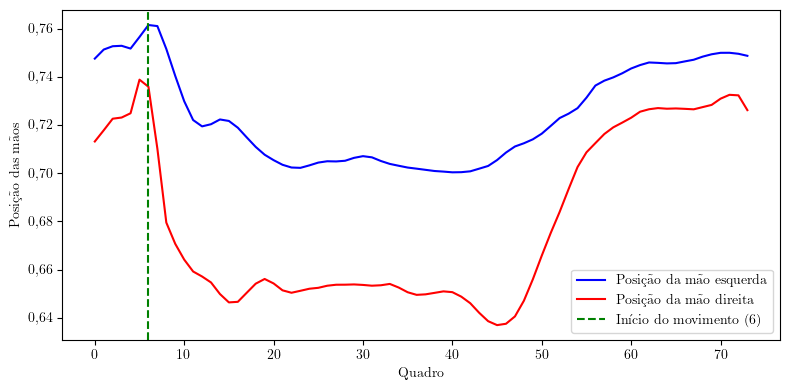

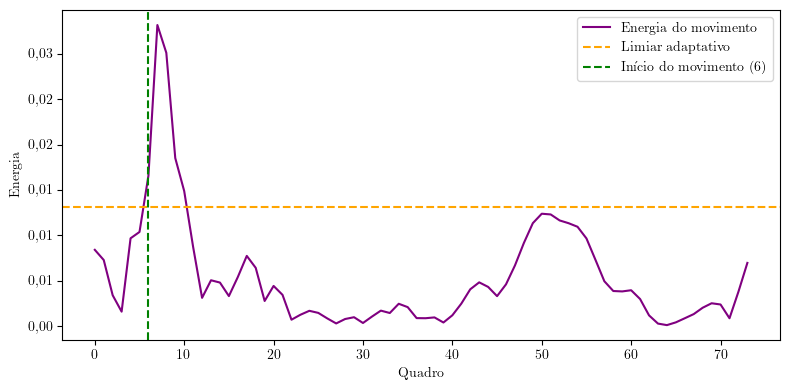

[Alergia_e2_ALE_e2_01_20] início movimento (adapt): 6

>>> Processando grupo: Alergia_e1_ALE_e1_02 (20 variações)
[Alergia_e1_ALE_e1_02_01] início movimento (adapt): 18

>>> Processando grupo: Alergia_e1_ALE_e1_04 (20 variações)
[Alergia_e1_ALE_e1_04_01] início movimento (adapt): 10

>>> Processando grupo: Alergia_AL_ALE_AL_04 (20 variações)
[Alergia_AL_ALE_AL_04_01] início movimento (adapt): 0

>>> Processando grupo: Alergia_e1_ALE_e1_01 (20 variações)
[Alergia_e1_ALE_e1_01_01] início movimento (adapt): 18

>>> Processando grupo: Alergia_AL_ALE_AL_03 (20 variações)
[Alergia_AL_ALE_AL_03_01] início movimento (adapt): 0

>>> Processando grupo: Alergia_MI_ALE_MI_02 (20 variações)
[Alergia_MI_ALE_MI_02_01] início movimento (adapt): 3

>>> Processando grupo: Alergia_e0_ALE_e0_01 (20 variações)
[Alergia_e0_ALE_e0_01_01] início movimento (adapt): 9

>>> Processando grupo: Alergia_SA_ALE_SA_04 (20 variações)
[Alergia_SA_ALE_SA_04_01] início movimento (adapt): 8

>>> Processando grupo: Alergia

In [6]:
usar_latex = True #Requer LaTeX instalado, use False para desativar nas figuras

#Figuras da detecção de movimento (posição das mãos e energia) de um vídeo de exemplo
detect_motion_start("../keypoints_data_ale_fri/Alergia/Alergia_e2_ALE_e2_01_20", num_frames, plot=True, pasta_figuras="../results/ale_fri")

#Treino: keypoints com augmentation (20 variações por vídeo)
preprocess_videos_motion("../keypoints_data_ale_fri", "../dataset_ale_fri/train", actions, num_frames, agrupar_variacoes=True)

#Validação: keypoints originais, sem augmentation
preprocess_videos_motion("../keypoints_data_ale_fri_original", "../dataset_ale_fri/val", actions, num_frames, agrupar_variacoes=False)

## Carregamento dos dados

In [7]:
#Cada sujeito é um fold da validação cruzada (leave-one-subject-out)
subject_names = ['AL','e0','e1','e2','e3','ME','MV','RO','SA','MI']

#Dados de cada sujeito
#X_all: vídeos de treino, com augmentation
#X_first: vídeos de validação, sem augmentation
subject_data = {
    s: {
        'X_all': [], 'y_all': [],
        'X_first': [], 'y_first': []
    }
    for s in subject_names
}

pad = len(str(num_frames - 1)) #Largura do zero à esquerda no nome dos arquivos (00.npy, 01.npy, ...)

def carrega_janelas(pasta, chave):
    #Lê os 30 frames de cada vídeo da pasta e guarda por sujeito em subject_data[sujeito][chave]
    for action in actions:
        action_dir = os.path.join(pasta, action)
        for video_folder in os.listdir(action_dir):
            #Identifica o sujeito pelo nome da pasta (ex.: Alergia_AL_ALE_AL_01_01 -> AL)
            m = re.search(r'_(%s)_' % '|'.join(subject_names), video_folder)
            if not m:
                raise ValueError(f"Não achou sujeito em {video_folder}")
            subj = m.group(1)

            video_dir = os.path.join(action_dir, video_folder)
            window = []
            for frame_num in range(num_frames):
                fname = f"{frame_num:0{pad}d}.npy"
                fpath = os.path.join(video_dir, fname)
                if not os.path.exists(fpath):
                    break
                res = np.load(fpath)
                window.append(res)

            if len(window) == num_frames:
                subject_data[subj]['X_' + chave].append(window)
                subject_data[subj]['y_' + chave].append(label_map[action])

carrega_janelas('../dataset_ale_fri/train', 'all')
carrega_janelas('../dataset_ale_fri/val', 'first')

#Converte para array e transforma os rótulos em one-hot
for s in subject_names:
    subject_data[s]['X_all'] = np.array(subject_data[s]['X_all'])
    subject_data[s]['y_all'] = to_categorical(subject_data[s]['y_all'], num_classes=len(actions))
    subject_data[s]['X_first'] = np.array(subject_data[s]['X_first'])
    subject_data[s]['y_first'] = to_categorical(subject_data[s]['y_first'], num_classes=len(actions))

## Parâmetros do modelo

In [8]:
neuronios = 32
dropout_recorrente = 0.1 #Taxa do dropout recorrente
batch_size = 32
taxa_aprendizado = 1e-3
weight_decay = 0.005 #Decaimento de peso do AdamW, fixo em todos os experimentos
epocas = 150


pasta_modelos = "models/ale_fri"
os.makedirs(pasta_modelos, exist_ok=True)

## Validação cruzada (10-fold, leave-one-subject-out)

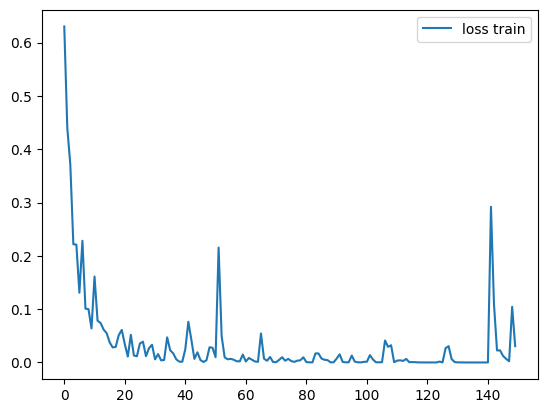

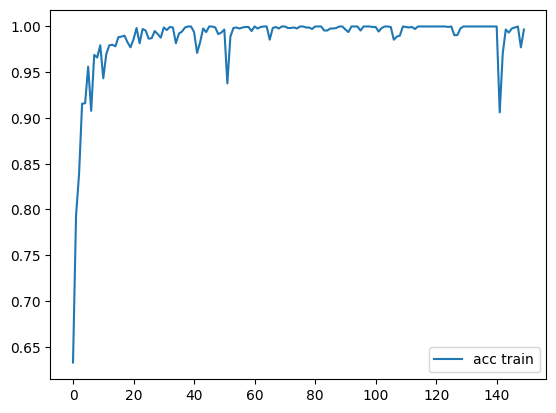

57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step

Fold 1 – Treino (AL excluído):
  Alergia: 1.0000
  Frieira: 1.0000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Fold 1 – Validação (AL): acc = 0.9000
  Alergia: 1.0000
  Frieira: 0.8000


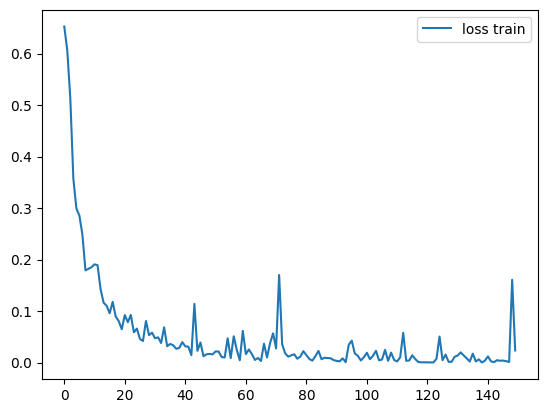

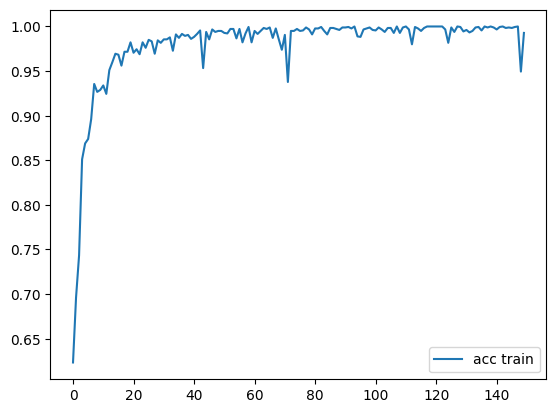

57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step

Fold 2 – Treino (e0 excluído):
  Alergia: 1.0000
  Frieira: 1.0000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Fold 2 – Validação (e0): acc = 0.9000
  Alergia: 1.0000
  Frieira: 0.8000


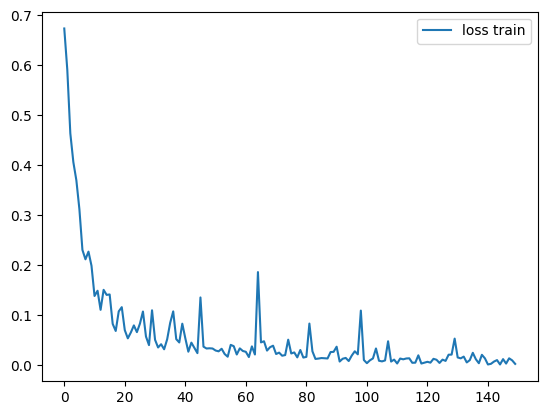

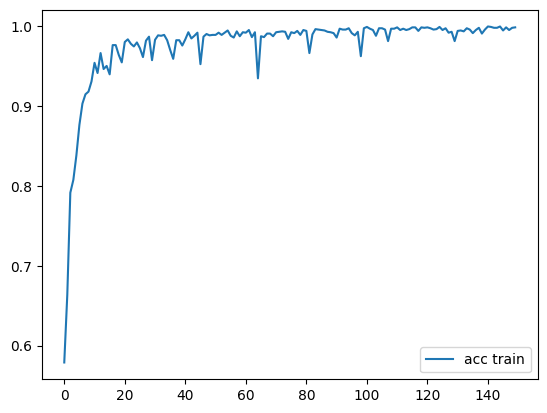

57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step

Fold 3 – Treino (e1 excluído):
  Alergia: 1.0000
  Frieira: 0.8878
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Fold 3 – Validação (e1): acc = 0.9000
  Alergia: 1.0000
  Frieira: 0.8000


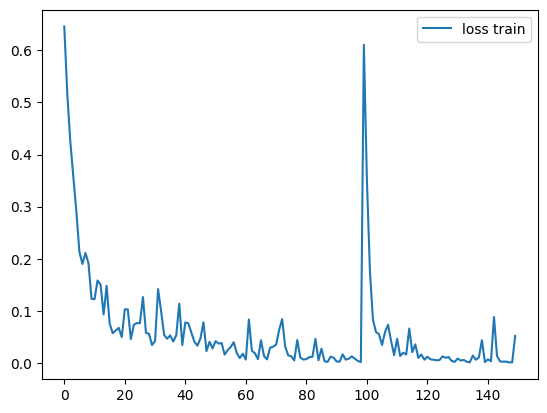

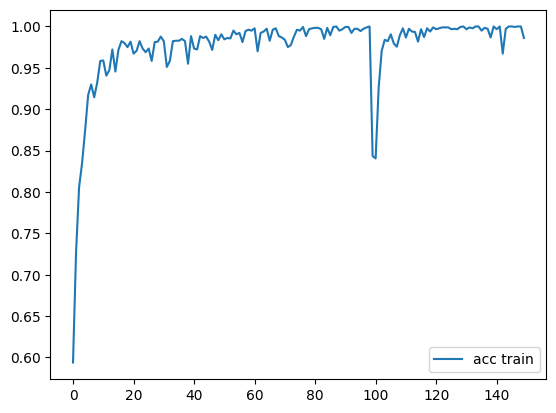

57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step

Fold 4 – Treino (e2 excluído):
  Alergia: 1.0000
  Frieira: 0.9778
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Fold 4 – Validação (e2): acc = 1.0000
  Alergia: 1.0000
  Frieira: 1.0000


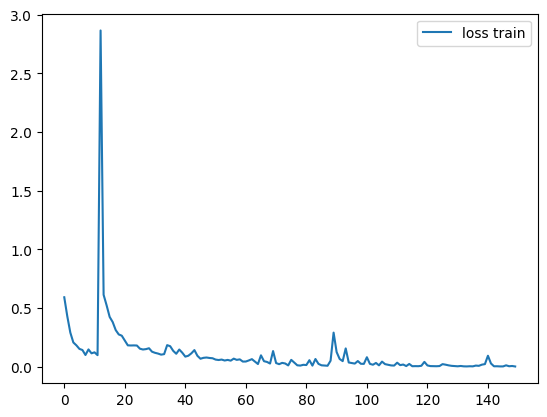

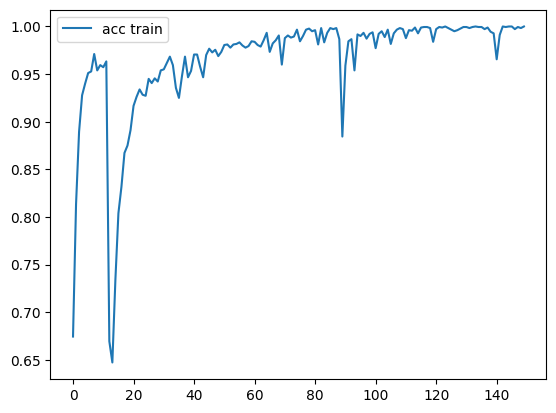

57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step

Fold 5 – Treino (e3 excluído):
  Alergia: 1.0000
  Frieira: 1.0000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Fold 5 – Validação (e3): acc = 1.0000
  Alergia: 1.0000
  Frieira: 1.0000


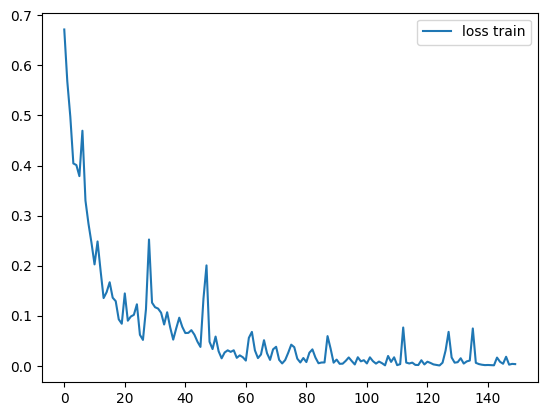

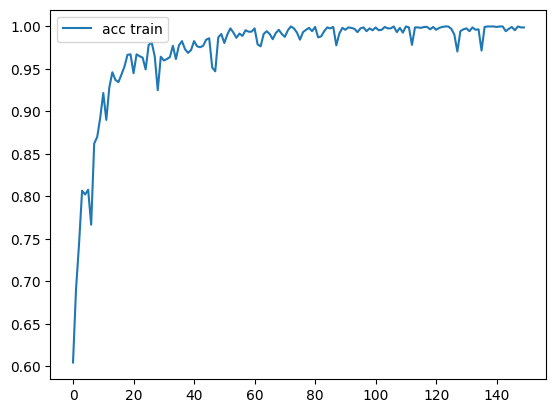

57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step

Fold 6 – Treino (ME excluído):
  Alergia: 1.0000
  Frieira: 1.0000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
Fold 6 – Validação (ME): acc = 1.0000
  Alergia: 1.0000
  Frieira: 1.0000


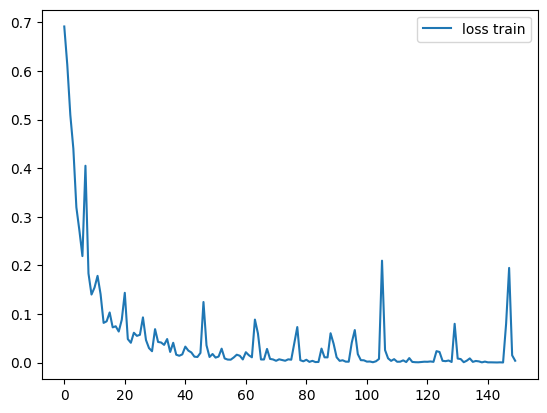

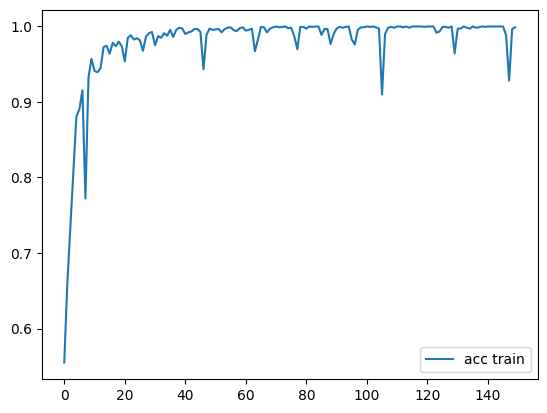

57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step

Fold 7 – Treino (MV excluído):
  Alergia: 1.0000
  Frieira: 1.0000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Fold 7 – Validação (MV): acc = 1.0000
  Alergia: 1.0000
  Frieira: 1.0000


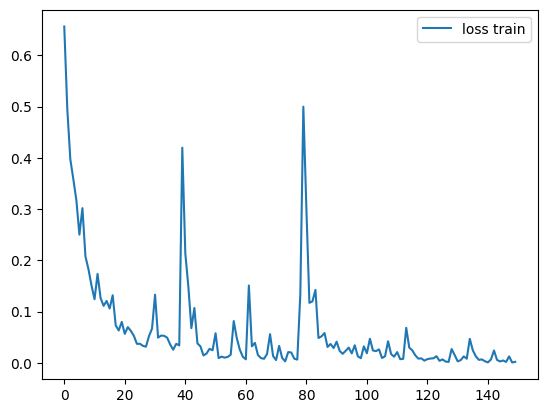

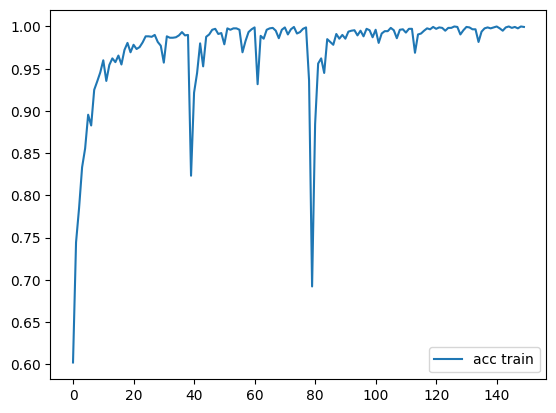

57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step

Fold 8 – Treino (RO excluído):
  Alergia: 1.0000
  Frieira: 1.0000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Fold 8 – Validação (RO): acc = 0.7000
  Alergia: 0.4000
  Frieira: 1.0000


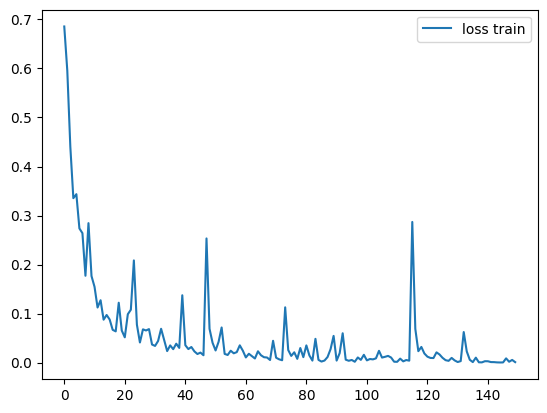

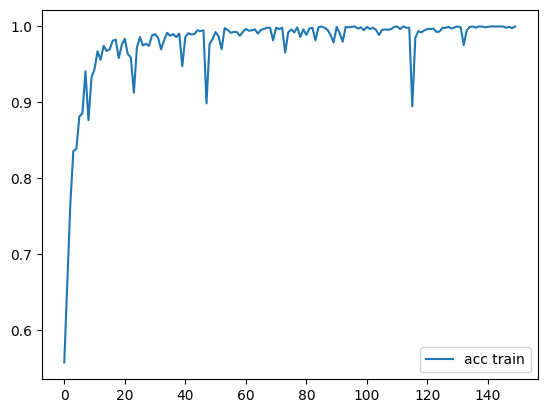

57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step

Fold 9 – Treino (SA excluído):
  Alergia: 1.0000
  Frieira: 1.0000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
Fold 9 – Validação (SA): acc = 1.0000
  Alergia: 1.0000
  Frieira: 1.0000


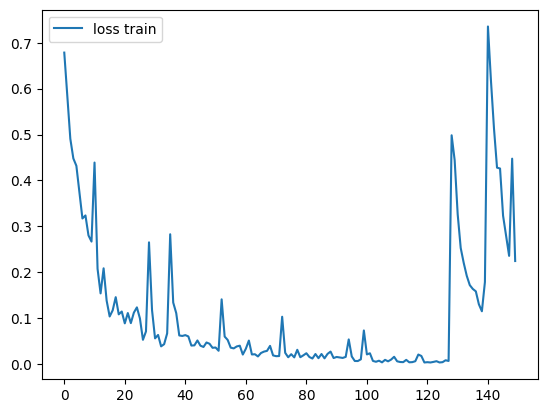

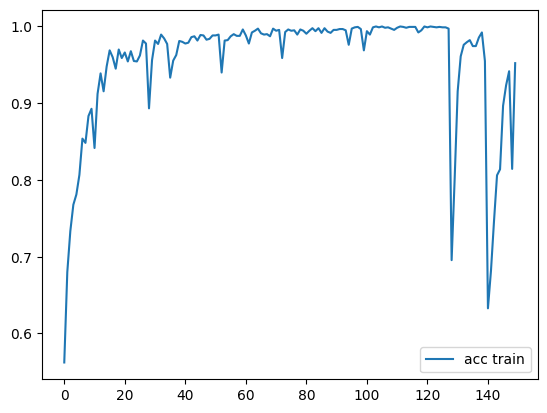

57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step

Fold 10 – Treino (MI excluído):
  Alergia: 0.9778
  Frieira: 0.9522
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Fold 10 – Validação (MI): acc = 1.0000
  Alergia: 1.0000
  Frieira: 1.0000

Acurácia Total = 0.9400  |  Desvio = 0.0917
Acurácia Geral = 0.9400


In [14]:
#Listas para juntar as predições de todos os folds
yhat_all = []
ytrue_all = []
fold_results = []

def class_acc(true, pred, labels):
    #Retorna a acurácia de cada classe
    acc = {}
    for i,lbl in enumerate(labels):
        idx = np.where(true == i)[0]
        acc[lbl] = np.mean(pred[idx]==true[idx]) if len(idx)>0 else 0
    return acc

labels = list(label_map.keys())

#Cada fold deixa um sujeito de fora para a validação
for i, val_subj in enumerate(subject_names):
    #Validação: sujeito excluído. Treino: todos os demais
    X_val, y_val = subject_data[val_subj]['X_first'], subject_data[val_subj]['y_first']

    X_train = np.concatenate([subject_data[s]['X_all'] for s in subject_names if s != val_subj])
    y_train = np.concatenate([subject_data[s]['y_all'] for s in subject_names if s != val_subj])

    model = Sequential()
    model.add(InputLayer(input_shape=(num_frames, 225)))
    model.add(Masking(mask_value=0.0))
    model.add(LSTM(neuronios,
        activation='relu',
        return_sequences=False,
        recurrent_dropout=dropout_recorrente))
    model.add(Dense(2, activation='softmax'))
    model.compile(optimizer=AdamW(taxa_aprendizado, weight_decay=weight_decay),
                  loss='categorical_crossentropy',
                  metrics=['categorical_accuracy'])

    hist = model.fit(X_train, y_train,
                     batch_size=batch_size, epochs=epocas, verbose=0)
    model.save(f"{pasta_modelos}/model_fold_{i+1}.keras")

    plt.plot(hist.history['loss'], label='loss train')
    plt.legend()
    plt.show()
    plt.plot(hist.history['categorical_accuracy'], label='acc train')
    plt.legend()
    plt.show()

    #Acurácia por classe no treino
    y_pred_tr = np.argmax(model.predict(X_train), axis=1)
    y_true_tr = np.argmax(y_train, axis=1)
    print(f"\nFold {i+1} – Treino ({val_subj} excluído):")
    for lbl, a in class_acc(y_true_tr, y_pred_tr, labels).items():
        print(f"  {lbl}: {a:.4f}")

    #Acurácia por classe na validação
    y_pred_v = np.argmax(model.predict(X_val), axis=1)
    y_true_v = np.argmax(y_val, axis=1)
    yhat_all.append(y_pred_v)
    ytrue_all.append(y_true_v)

    acc_v = np.mean(y_pred_v == y_true_v)
    fold_results.append(acc_v)
    print(f"Fold {i+1} – Validação ({val_subj}): acc = {acc_v:.4f}")
    for lbl, a in class_acc(y_true_v, y_pred_v, labels).items():
        print(f"  {lbl}: {a:.4f}")

#Média e desvio padrão da acurácia entre os folds
media = np.mean(fold_results)
std = np.std(fold_results)
print(f"\nAcurácia Total = {media:.4f}  |  Desvio = {std:.4f}")

#Acurácia geral, juntando as predições de todos os folds
y_true_final = np.concatenate(ytrue_all)
y_pred_final = np.concatenate(yhat_all)
acc_final = np.mean(y_pred_final == y_true_final)
print(f"Acurácia Geral = {acc_final:.4f}")

## Modelo final (treinado com todos os dados)

Shape X_all: (2000, 30, 225)
Shape y_all: (2000, 2)
Epoch 1/150
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - categorical_accuracy: 0.5240 - loss: 0.6949
Epoch 2/150
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - categorical_accuracy: 0.6990 - loss: 0.5646
Epoch 3/150
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - categorical_accuracy: 0.8000 - loss: 0.4221
Epoch 4/150
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - categorical_accuracy: 0.8185 - loss: 0.4063
Epoch 5/150
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - categorical_accuracy: 0.8800 - loss: 0.2773
Epoch 6/150
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - categorical_accuracy: 0.8975 - loss: 0.2426
Epoch 7/150
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - categorical_accuracy: 0.9170 - loss: 0.2082
Epoch 8/150
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - categorical_accuracy: 0.9305 - loss: 0.1792
Epoch 9/150
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - categorical_accuracy: 0.9505 - loss: 0.1346
Epoch 10/150
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - categorical

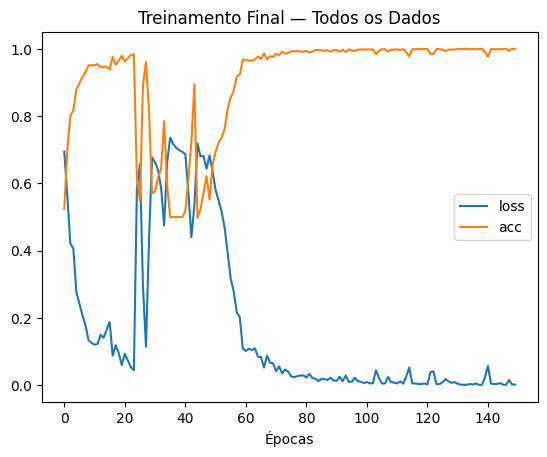

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step

Acurácia total (auto-avaliação): 1.0000


In [15]:
#Junta os dados de treino de todos os sujeitos
X_all = np.concatenate([subject_data[s]['X_all'] for s in subject_names])
y_all = np.concatenate([subject_data[s]['y_all'] for s in subject_names])

print(f"Shape X_all: {X_all.shape}")
print(f"Shape y_all: {y_all.shape}")

model = Sequential()
model.add(InputLayer(input_shape=(num_frames, 225)))
model.add(Masking(mask_value=0.0))
model.add(LSTM(neuronios,
               activation='relu',
               return_sequences=False,
               recurrent_dropout=dropout_recorrente))
model.add(Dense(2, activation='softmax'))
model.compile(optimizer=AdamW(taxa_aprendizado, weight_decay=weight_decay),
              loss='categorical_crossentropy',
              metrics=['categorical_accuracy'])

#Treina com todos os sujeitos (X_all e y_all)
hist = model.fit(X_all, y_all,
                 batch_size=batch_size,
                 epochs=epocas,
                 verbose=1)

model.save(f"{pasta_modelos}/model_final_ale_fri.keras")

#Curvas de perda e acurácia do treino
plt.plot(hist.history['loss'], label='loss')
plt.plot(hist.history['categorical_accuracy'], label='acc')
plt.legend()
plt.title("Treinamento Final — Todos os Dados")
plt.xlabel("Épocas")
plt.show()

#Acurácia do modelo final nos próprios dados de treino
y_pred = np.argmax(model.predict(X_all), axis=1)
y_true = np.argmax(y_all, axis=1)

acc_final = np.mean(y_pred == y_true)
print(f"\nAcurácia total (auto-avaliação): {acc_final:.4f}")